In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

In [3]:
def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['w'])
        nss = sum(df[df.bs==+1]['w'])
    elif (ob == 'bs_ch'):
        nos = sum(df[df.bs_ch==-1]['w'])
        nss = sum(df[df.bs_ch==+1]['w'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    n_array = []
    wtot_array = []
    for i in range(0, len(w_array)):
        n_array.append( df[df.w == w_array[i]].shape[0] )
        wtot_array.append( sum(df[df.w == w_array[i]]['w']) )
    n = 0
    for i in range(0, len(w_array)):
        if (wtot_array[i] != 0):
            n += wtot_array[i]*n_array[i]/sum(wtot_array)
    rc_err = 2*np.sqrt(p*(1-p)/n)
    return rc, rc_err

In [4]:
def calc_hist(vals, bins=10, weights=None, density=False):
    
    if weights is None:
        weights = np.ones(vals.shape)
    
    # compute histogram
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    
    # compute which bins the values are in
    digits = np.digitize(vals, bins)

    # compute the errors per bin
    # note that lowest bin value that digitize returns is 1
    # hence the range in the following list comprehension should start at 1
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])

    # handle normalization
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
        
    return hist, errs, bins

read jets from txt files

In [5]:
df0 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_50pthat_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df1 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_45pthat50_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df2 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_40pthat45_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df3 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_35pthat40_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df4 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_30pthat35_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df5 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_25pthat30_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df6 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_20pthat25_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df7 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_15pthat20_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df8 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_11pthat15_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df9 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_10pthat11_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)

In [89]:
w0=(float)(df0.iloc[df0.shape[0]-1]['xsec'])/200000
w1=(float)(df1.iloc[df1.shape[0]-1]['xsec'])/200000
w2=(float)(df2.iloc[df2.shape[0]-1]['xsec'])/200000
w3=(float)(df3.iloc[df3.shape[0]-1]['xsec'])/200000
w4=(float)(df4.iloc[df4.shape[0]-1]['xsec'])/200000
w5=(float)(df5.iloc[df5.shape[0]-1]['xsec'])/200000
w6=(float)(df6.iloc[df6.shape[0]-1]['xsec'])/200000
w7=(float)(df7.iloc[df7.shape[0]-1]['xsec'])/200000
w8=(float)(df8.iloc[df8.shape[0]-1]['xsec'])/200000
w9=(float)(df9.iloc[df9.shape[0]-1]['xsec'])/200000
df0['w']=np.ones(df0.shape[0])*w0
df1['w']=np.ones(df1.shape[0])*w1
df2['w']=np.ones(df2.shape[0])*w2
df3['w']=np.ones(df3.shape[0])*w3
df4['w']=np.ones(df4.shape[0])*w4
df5['w']=np.ones(df5.shape[0])*w5
df6['w']=np.ones(df6.shape[0])*w6
df7['w']=np.ones(df7.shape[0])*w7
df8['w']=np.ones(df8.shape[0])*w8
df9['w']=np.ones(df9.shape[0])*w9
df = pd.concat([df0,df1,df2,df3,df4,df5,df6,df7,df8,df9])
df_herwig = df[['pt','b_ch','w','y1_ch','y2_ch','phi1_ch','phi2_ch','pts','bs_ch','y1s_ch','y2s_ch','phi1s_ch','phi2s_ch']]

In [9]:
df_allreco = applyCut(df_herwig, 'pts>15 and bs_ch!=-9 and bs_ch!=0')

In [11]:
df = applyCut(df_herwig, 'pts>15 and bs_ch!=-9 and bs_ch!=0 and pt>5 and b_ch!=-9 and b_ch!=0')

In [90]:
df_alltruth = applyCut(df_herwig, 'pt>5 and b_ch!=-9 and b_ch!=0')

In [13]:
distance1 = []
distance2 = []
for i in range(0,df.shape[0]):
    phi1small = min(df.iloc[i]['phi1_ch'], df.iloc[i]['phi1s_ch'])
    phi1large = max(df.iloc[i]['phi1_ch'], df.iloc[i]['phi1s_ch'])
    phi2small = min(df.iloc[i]['phi2_ch'], df.iloc[i]['phi2s_ch'])
    phi2large = max(df.iloc[i]['phi2_ch'], df.iloc[i]['phi2s_ch'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df.iloc[i]['phi1_ch'], df.iloc[i]['phi1s_ch'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df.iloc[i]['y1_ch']-df.iloc[i]['y1s_ch'])**2))
    distance2.append(np.sqrt(dphi2**2+(df.iloc[i]['y2_ch']-df.iloc[i]['y2s_ch'])**2))
df['distance1'] = distance1
df['distance2'] = distance2

/tmp/ipykernel_29310/3926186177.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['distance1'] = distance1
/tmp/ipykernel_29310/3926186177.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['distance2'] = distance2


In [14]:
distance1 = []
distance2 = []
for i in range(0,df_allreco.shape[0]):
    phi1small = min(df_allreco.iloc[i]['phi1_ch'], df_allreco.iloc[i]['phi1s_ch'])
    phi1large = max(df_allreco.iloc[i]['phi1_ch'], df_allreco.iloc[i]['phi1s_ch'])
    phi2small = min(df_allreco.iloc[i]['phi2_ch'], df_allreco.iloc[i]['phi2s_ch'])
    phi2large = max(df_allreco.iloc[i]['phi2_ch'], df_allreco.iloc[i]['phi2s_ch'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df_allreco.iloc[i]['phi1_ch'], df_allreco.iloc[i]['phi1s_ch'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df_allreco.iloc[i]['y1_ch']-df_allreco.iloc[i]['y1s_ch'])**2))
    distance2.append(np.sqrt(dphi2**2+(df_allreco.iloc[i]['y2_ch']-df_allreco.iloc[i]['y2s_ch'])**2))
df_allreco['distance1'] = distance1
df_allreco['distance2'] = distance2

/tmp/ipykernel_29310/4264877438.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_allreco['distance1'] = distance1
/tmp/ipykernel_29310/4264877438.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_allreco['distance2'] = distance2


In [38]:
df.to_csv('herwig.csv',index=False)
df_allreco.to_csv('herwig_allreco.csv',index=False)

read jet df from csv files

In [5]:
df = pd.read_csv('herwig.csv')
df_allreco = pd.read_csv('herwig_allreco.csv')
df_alltruth = pd.read_csv('herwig_alltruth.csv')

FileNotFoundError: [Errno 2] No such file or directory: 'herwig_alltruth.csv'

fake df

In [13]:
df_allfake = applyCut(df_allreco, 'pt<0 or b_ch==-9 or b_ch==0 or distance1>0.02 or distance2>0.02')

match df

In [14]:
df_match = applyCut(df, 'distance1 < 0.02 and distance2 < 0.02')

In [15]:
df_match.shape[0]

1055362

create arrays for rc and rc errors

In [16]:
w_array = np.unique(df_allreco['w'])

In [17]:
df_allreco_pts_array = [ df_allreco[(df_allreco.pts>15) & (df_allreco.pts<20)],\
                       df_allreco[(df_allreco.pts>20) & (df_allreco.pts<25)],\
                       df_allreco[(df_allreco.pts>25) & (df_allreco.pts<30)],\
                       df_allreco[(df_allreco.pts>30) & (df_allreco.pts<40)] ]

In [18]:
rc_allreco_bs_ch_vs_pts_array = []
rc_err_allreco_bs_ch_vs_pts_array = []
for i in range(0, len(df_allreco_pts_array)):
    rc_allreco_bs_ch_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs_ch')[0])
    rc_err_allreco_bs_ch_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs_ch')[1])

In [73]:
df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)] ]

In [74]:
rc_match_bs_ch_vs_pts_array = []
rc_err_match_bs_ch_vs_pts_array = []
for i in range(0, len(df_match_pts_array)):
    rc_match_bs_ch_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs_ch')[0])
    rc_err_match_bs_ch_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs_ch')[1])

In [21]:
df_allfake_pts_array = [ df_allfake[(df_allfake.pts>15) & (df_allfake.pts<20)],\
                       df_allfake[(df_allfake.pts>20) & (df_allfake.pts<25)],\
                       df_allfake[(df_allfake.pts>25) & (df_allfake.pts<30)],\
                       df_allfake[(df_allfake.pts>30) & (df_allfake.pts<40)] ]

In [22]:
rc_allfake_bs_ch_vs_pts_array = []
rc_err_allfake_bs_ch_vs_pts_array = []
for i in range(0, len(df_allfake_pts_array)):
    rc_allfake_bs_ch_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs_ch')[0])
    rc_err_allfake_bs_ch_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs_ch')[1])

In [48]:
df_fakejet_pts_array = [ df_fakejet[(df_fakejet.pts>15) & (df_fakejet.pts<20)],\
                       df_fakejet[(df_fakejet.pts>20) & (df_fakejet.pts<25)],\
                       df_fakejet[(df_fakejet.pts>25) & (df_fakejet.pts<30)],\
                       df_fakejet[(df_fakejet.pts>30) & (df_fakejet.pts<40)] ]

In [49]:
rc_fakejet_bs_ch_vs_pts_array = []
rc_err_fakejet_bs_ch_vs_pts_array = []
for i in range(0, len(df_fakejet_pts_array)):
    rc_fakejet_bs_ch_vs_pts_array.append(getRcAndErr(df_fakejet_pts_array[i], 'bs_ch')[0])
    rc_err_fakejet_bs_ch_vs_pts_array.append(getRcAndErr(df_fakejet_pts_array[i], 'bs_ch')[1])

In [50]:
df_fakecorr_pts_array = [ df_fakecorr[(df_fakecorr.pts>15) & (df_fakecorr.pts<20)],\
                       df_fakecorr[(df_fakecorr.pts>20) & (df_fakecorr.pts<25)],\
                       df_fakecorr[(df_fakecorr.pts>25) & (df_fakecorr.pts<30)],\
                       df_fakecorr[(df_fakecorr.pts>30) & (df_fakecorr.pts<40)] ]

In [51]:
rc_fakecorr_bs_ch_vs_pts_array = []
rc_err_fakecorr_bs_ch_vs_pts_array = []
for i in range(0, len(df_fakecorr_pts_array)):
    rc_fakecorr_bs_ch_vs_pts_array.append(getRcAndErr(df_fakecorr_pts_array[i], 'bs_ch')[0])
    rc_err_fakecorr_bs_ch_vs_pts_array.append(getRcAndErr(df_fakecorr_pts_array[i], 'bs_ch')[1])

Text(0.5, 1.0, 'Matching cut: truth pT > 5 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.02')

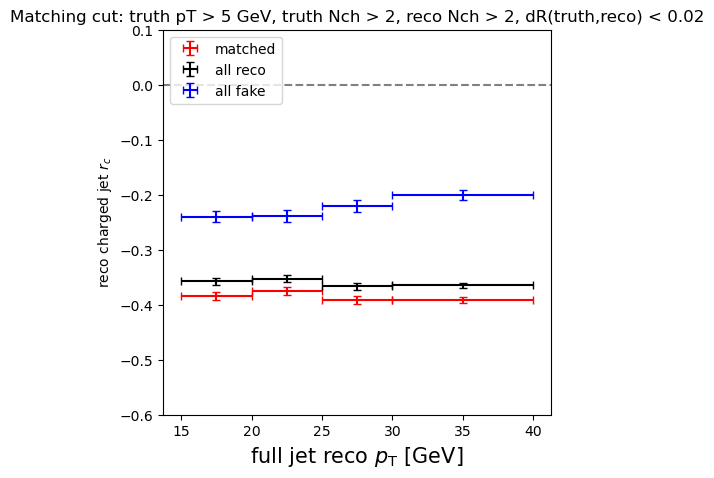

In [23]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35], rc_match_bs_ch_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_match_bs_ch_vs_pts_array, capsize=3, color='r', ls='none', label='matched')
plt.errorbar([17.5, 22.5, 27.5, 35], rc_allreco_bs_ch_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_allreco_bs_ch_vs_pts_array, capsize=3, color='k', ls='none', label='all reco')
plt.errorbar([17.5, 22.5, 27.5, 35], rc_allfake_bs_ch_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_allfake_bs_ch_vs_pts_array, capsize=3, color='b', ls='none', label='all fake')
#plt.errorbar([17.5, 22.5, 27.5, 35], rc_fakejet_bs_ch_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_fakejet_bs_ch_vs_pts_array, capsize=3, color='orange', ls='none', label='fake jets')
#plt.errorbar([17.5, 22.5, 27.5, 35], rc_fakecorr_bs_ch_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_fakecorr_bs_ch_vs_pts_array, capsize=3, ls='none', label='fake corr')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')
plt.title('Matching cut: truth pT > 5 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.02')

In [54]:
np.array(rc_allreco_bs_ch_vs_pts_array)-np.array(rc_match_bs_ch_vs_pts_array)

array([0.02635192, 0.02288373, 0.02536242, 0.02701265])

fake dist

In [24]:
ob = 'bs_ch'
range_low = -1.2
range_high = 1.2
bins = 2

In [25]:
df_match_20 = applyCut(df_match, '20 < pts < 25')
df_allreco_20 = applyCut(df_allreco, '20 < pts < 25')
df_fake_20 = applyCut(df_allfake, '20 < pts < 25')
#df_fakejet_20 = applyCut(df_fakejet, '20 < pts < 25')
#df_fakecorr_20 = applyCut(df_fakecorr, '20 < pts < 25')
#df_notfakejet_20 = applyCut(df_notfakejet, '20 < pts < 25')

In [26]:
y_match_rec,yerr_match_rec,x = calc_hist(df_match_20[ob], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_20['w'], density=True)
y_allreco_rec,yerr_allreco_rec,x = calc_hist(df_allreco_20[ob], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_allreco_20['w'], density=True)
y_fake_rec,yerr_fake_rec,x = calc_hist(df_fake_20[ob], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fake_20['w'], density=True)
#y_fakejet_rec,yerr_fakejet_rec,x = calc_hist(df_fakejet_20[ob], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fakejet_20['w'], density=True)
#y_notfakejet_rec,yerr_notfakejet_rec,x = calc_hist(df_notfakejet_20[ob], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_notfakejet_20['w'], density=True)
#y_fakecorr_rec,yerr_fakecorr_rec,x = calc_hist(df_fakecorr_20[ob], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fakecorr_20['w'], density=True)

In [27]:
print(y_fake_rec/sum(y_fake_rec))
print(yerr_fake_rec/sum(y_fake_rec))

[0.61919054 0.38080946]
[0.02022914 0.01355965]


In [28]:
df_match_25 = applyCut(df_match, '25 < pts < 30')
df_allreco_25 = applyCut(df_allreco, '25 < pts < 30')
df_fake_25 = applyCut(df_allfake, '25 < pts < 30')
#df_fakejet_25 = applyCut(df_fakejet, '25 < pts < 30')
#df_fakecorr_25 = applyCut(df_fakecorr, '25 < pts < 30')
#df_notfakejet_25 = applyCut(df_notfakejet, '25 < pts < 30')

In [29]:
y_match_rec,yerr_match_rec,x = calc_hist(df_match_25[ob], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_25['w'])
y_allreco_rec,yerr_allreco_rec,x = calc_hist(df_allreco_25[ob], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_allreco_25['w'])
y_fake_rec,yerr_fake_rec,x = calc_hist(df_fake_25[ob], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fake_25['w'])
#y_fakejet_rec,yerr_fakejet_rec,x = calc_hist(df_fakejet_25[ob], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fakejet_25['w'])
#y_fakecorr_rec,yerr_fakecorr_rec,x = calc_hist(df_fakecorr_25[ob], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fakecorr_25['w'])
#y_notfakejet_rec,yerr_notfakejet_rec,x = calc_hist(df_notfakejet_25[ob], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_notfakejet_25['w'])

In [30]:
print(y_fake_rec/sum(y_fake_rec))
print(yerr_fake_rec/sum(y_fake_rec))

[0.61062968 0.38937032]
[0.01833678 0.01507328]


In [31]:
df_match_30 = applyCut(df_match, '30 < pts < 40')
df_allreco_30 = applyCut(df_allreco, '30 < pts < 40')
df_fake_30 = applyCut(df_allfake, '30 < pts < 40')
#df_fakejet_30 = applyCut(df_fakejet, '30 < pts < 40')
#df_fakecorr_30 = applyCut(df_fakecorr, '30 < pts < 40')
#df_notfakejet_30 = applyCut(df_notfakejet, '30 < pts < 40')

In [32]:
y_match_rec,yerr_match_rec,x = calc_hist(df_match_30[ob], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_30['w'])
y_allreco_rec,yerr_allreco_rec,x = calc_hist(df_allreco_30[ob], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_allreco_30['w'])
y_fake_rec,yerr_fake_rec,x = calc_hist(df_fake_30[ob], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fake_30['w'])
#y_fakejet_rec,yerr_fakejet_rec,x = calc_hist(df_fakejet_30[ob], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fakejet_30['w'])
#y_fakecorr_rec,yerr_fakecorr_rec,x = calc_hist(df_fakecorr_30[ob], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fakecorr_30['w'])

In [33]:
print(y_fake_rec/sum(y_fake_rec))
print(yerr_fake_rec/sum(y_fake_rec))

[0.60007008 0.39992992]
[0.01274155 0.01891553]


pT correction

In [44]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)] ]

In [66]:
rc_match_bs_ch_vs_pt_array = []
rc_err_match_bs_ch_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_ch_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs_ch')[0])
    rc_err_match_bs_ch_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs_ch')[1])

In [78]:
df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)] ]

In [79]:
rc_match_bs_ch_vs_pts_array = []
rc_err_match_bs_ch_vs_pts_array = []
for i in range(0, len(df_match_pts_array)):
    rc_match_bs_ch_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs_ch')[0])
    rc_err_match_bs_ch_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs_ch')[1])

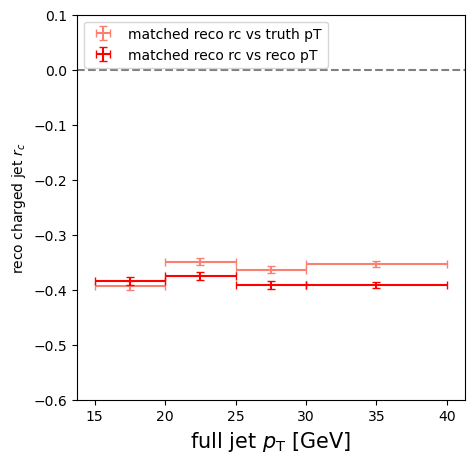

In [80]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35], rc_match_bs_ch_vs_pt_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_match_bs_ch_vs_pt_array, capsize=3, color='salmon', ls='none', label='matched reco rc vs truth pT')
plt.errorbar([17.5, 22.5, 27.5, 35], rc_match_bs_ch_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_match_bs_ch_vs_pts_array, capsize=3, color='r', ls='none', label='matched reco rc vs reco pT')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')
#plt.title('Matching cut: truth pT > 5 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.02')

In [81]:
rc_match_bs_ch_vs_pts_array

[-0.38343296630434354,
 -0.3756057447167346,
 -0.39178490858725995,
 -0.39173862206904786]

rc correction

In [47]:
rc_match_b_ch_vs_pt_array = []
rc_err_match_b_ch_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_b_ch_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'b_ch')[0])
    rc_err_match_b_ch_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'b_ch')[1])

In [91]:
df_alltruth_pt_array = [ df_alltruth[(df_alltruth.pt>15) & (df_alltruth.pt<20)],\
                       df_alltruth[(df_alltruth.pt>20) & (df_alltruth.pt<25)],\
                       df_alltruth[(df_alltruth.pt>25) & (df_alltruth.pt<30)],\
                       df_alltruth[(df_alltruth.pt>30) & (df_alltruth.pt<40)] ]

In [92]:
rc_alltruth_b_ch_vs_pt_array = []
rc_err_alltruth_b_ch_vs_pt_array = []
for i in range(0, len(df_alltruth_pt_array)):
    rc_alltruth_b_ch_vs_pt_array.append(getRcAndErr(df_alltruth_pt_array[i], 'b_ch')[0])
    rc_err_alltruth_b_ch_vs_pt_array.append(getRcAndErr(df_alltruth_pt_array[i], 'b_ch')[1])

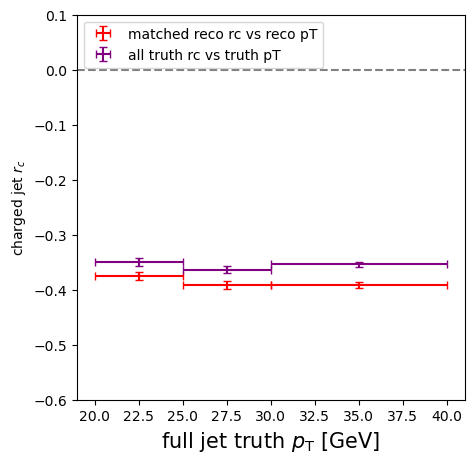

In [93]:
fig=plt.figure(figsize=(5,5))
#plt.errorbar([22.5, 27.5, 35], rc_match_b_ch_vs_pt_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_b_ch_vs_pt_array[1:], capsize=3, color='purple', ls='none', label='matched truth rc vs truth pT')
#plt.errorbar([22.5, 27.5, 35], rc_match_bs_ch_vs_pt_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_ch_vs_pt_array[1:], capsize=3, color='salmon', ls='none', label='matched reco rc vs truth pT')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_ch_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_ch_vs_pts_array[1:], capsize=3, color='r', ls='none', label='matched reco rc vs reco pT')
plt.errorbar([22.5, 27.5, 35], rc_match_b_ch_vs_pt_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_b_ch_vs_pt_array[1:], capsize=3, color='purple', ls='none', label='all truth rc vs truth pT')
plt.xlabel('full jet truth $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')
#plt.title('Matching cut: truth pT > 5 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.02')